In [1]:
# Cell 1 — Mount Drive, paths, imports
from google.colab import drive
drive.mount('/content/drive')

import sys, json, importlib
from pathlib import Path
import numpy as np
import pandas as pd

RAW_DIR     = Path("/content/drive/MyDrive/CMAPSSData")
PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
PROC_DIR    = PROJECT_DIR / "data" / "processed" / "FD001"
PREP_REPORT = PROJECT_DIR / "reports" / "preprocessing" / "FD001"
for p in (PROC_DIR, PREP_REPORT):
    p.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT_DIR))
SEED = 42
FD = "FD001"
print("Ready")

Mounted at /content/drive
Ready


In [2]:
%%writefile /content/drive/MyDrive/Predictive_Maintenance_RUL/src/preprocessing.py
"""
preprocessing.py — Leakage-safe preprocessing for NASA C-MAPSS.

Why this file exists: training notebooks, evaluation and the FastAPI backend must
transform data in *exactly* the same way. Every "learned" step (feature selection,
scaling) is fitted on TRAINING engines only, then frozen and re-applied elsewhere.
"""
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from src.data_loader import FEATURE_CANDIDATES, ID_COLS, SETTING_COLS

TARGET = "RUL"


# ----------------------------------------------------------------------------- labels
def add_train_rul(df: pd.DataFrame, cap=None) -> pd.DataFrame:
    """RUL = (engine's last cycle) - (current cycle). Optional upper cap (piecewise-linear target).
    Valid ONLY for run-to-failure (training) trajectories."""
    out = df.copy()
    last_cycle = out.groupby("engine_id")["cycle"].transform("max")
    out[TARGET] = (last_cycle - out["cycle"]).astype(float)
    if cap is not None:
        out[TARGET] = out[TARGET].clip(upper=cap)
    return out


def add_test_rul(test_df: pd.DataFrame, rul_df: pd.DataFrame) -> pd.DataFrame:
    """FINAL EVALUATION ONLY. RUL at every test row = true RUL at last cycle + cycles remaining
    until that last cycle. Never use for training, tuning or model selection."""
    out = test_df.copy()
    last_cycle = out.groupby("engine_id")["cycle"].transform("max")
    rul_at_last = out["engine_id"].map(rul_df.set_index("engine_id")["true_rul"])
    if rul_at_last.isna().any():
        raise ValueError("Some test engines have no entry in the RUL file.")
    out[TARGET] = (rul_at_last + (last_cycle - out["cycle"])).astype(float)
    return out


# ----------------------------------------------------------------------------- splitting
def split_engines(df: pd.DataFrame, val_fraction: float = 0.2, seed: int = 42):
    """Split by ENGINE, not by row: every row of an engine lands in exactly one split."""
    ids = np.sort(df["engine_id"].unique())
    n_val = int(round(len(ids) * val_fraction))
    rng = np.random.default_rng(seed)
    val_ids = np.sort(rng.choice(ids, size=n_val, replace=False))
    train_ids = np.setdiff1d(ids, val_ids)
    return train_ids.tolist(), val_ids.tolist()


# ----------------------------------------------------------------------------- feature selection
def count_regimes(df: pd.DataFrame) -> int:
    """Number of distinct operating conditions, found by rounding settings to a coarse grid."""
    rounded = df[SETTING_COLS].round({"op_setting_1": 0, "op_setting_2": 2, "op_setting_3": 0})
    return int(len(rounded.drop_duplicates()))


def select_features(train_df: pd.DataFrame, candidates=FEATURE_CANDIDATES, min_unique: int = 3):
    """Data-driven feature selection, computed on the TRAINING split only.
    Rules (documented in Phase 3):
      1. Drop features with fewer than `min_unique` distinct values (constant / near-constant).
      2. If the data has a single operating regime, drop the operational settings
         (they are then only measurement noise around one set-point).
    Returns (kept_features_in_original_order, {dropped_feature: reason})."""
    dropped = {}
    n_unique = train_df[candidates].nunique()
    for col in candidates:
        if n_unique[col] < min_unique:
            dropped[col] = f"only {n_unique[col]} distinct value(s) in training split"
    if count_regimes(train_df) == 1:
        for col in SETTING_COLS:
            dropped.setdefault(col, "single operating regime -> setting is noise")
    kept = [c for c in candidates if c not in dropped]
    return kept, dropped


# ----------------------------------------------------------------------------- preprocessor
_SCALERS = {"standard": StandardScaler, "minmax": MinMaxScaler}


class CMAPSSPreprocessor:
    """Fit on training engines -> transform train / validation / test / API input identically."""

    def __init__(self, scaler: str = "standard", feature_cols=None):
        if scaler not in _SCALERS:
            raise ValueError(f"scaler must be one of {list(_SCALERS)}")
        self.scaler_name = scaler
        self.feature_cols = list(feature_cols) if feature_cols is not None else None
        self.dropped_features = {}
        self.scaler = None

    # -- validation shared by fit and transform
    def _validate(self, df: pd.DataFrame, cols):
        missing = [c for c in ID_COLS + list(cols) if c not in df.columns]
        if missing:
            raise ValueError(f"Missing required columns: {missing}")
        bad_types = [c for c in cols if not pd.api.types.is_numeric_dtype(df[c])]
        if bad_types:
            raise ValueError(f"Non-numeric columns: {bad_types}")
        n_nan = int(df[list(cols)].isna().sum().sum())
        if n_nan:
            raise ValueError(f"Input contains {n_nan} missing values; C-MAPSS pipeline does not impute.")

    def fit(self, train_df: pd.DataFrame):
        if self.feature_cols is None:
            self.feature_cols, self.dropped_features = select_features(train_df)
        self._validate(train_df, self.feature_cols)
        self.scaler = _SCALERS[self.scaler_name]().fit(train_df[self.feature_cols])
        return self

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        if self.scaler is None:
            raise RuntimeError("Call fit() on training data before transform().")
        self._validate(df, self.feature_cols)
        keep = ID_COLS + ([TARGET] if TARGET in df.columns else [])
        out = df[keep].copy()
        scaled = self.scaler.transform(df[self.feature_cols])   # DataFrame in -> column order enforced
        out[self.feature_cols] = scaled
        return out

    # -- persistence: scaler (joblib) + human-readable config (JSON)
    def save(self, directory):
        directory = Path(directory)
        directory.mkdir(parents=True, exist_ok=True)
        joblib.dump(self.scaler, directory / "scaler.joblib")
        config = {"scaler": self.scaler_name, "feature_cols": self.feature_cols,
                  "dropped_features": self.dropped_features}
        (directory / "preprocessing_config.json").write_text(json.dumps(config, indent=2))

    @classmethod
    def load(cls, directory):
        directory = Path(directory)
        config = json.loads((directory / "preprocessing_config.json").read_text())
        obj = cls(scaler=config["scaler"], feature_cols=config["feature_cols"])
        obj.dropped_features = config["dropped_features"]
        obj.scaler = joblib.load(directory / "scaler.joblib")
        return obj

Writing /content/drive/MyDrive/Predictive_Maintenance_RUL/src/preprocessing.py


In [3]:
# Cell 3 — Load FD001 and create training RUL labels (uncapped)
import src.data_loader as dl, src.preprocessing as pp
importlib.reload(dl); importlib.reload(pp)

d = dl.load_dataset(FD, RAW_DIR)
train_full = pp.add_train_rul(d["train"])          # cap=None: raw labels; capping is tested in Part B

# Verify label logic on every engine: last row = 0, first row = lifetime-1, decreases by exactly 1
g = train_full.groupby("engine_id")
assert (g["RUL"].last() == 0).all()
assert (g["RUL"].first() == g["cycle"].max() - 1).all()
assert (g["RUL"].diff().dropna() == -1).all()
print("✅ RUL labels verified for all", train_full['engine_id'].nunique(), "engines")
display(train_full.loc[train_full.engine_id == 1, ["engine_id", "cycle", "RUL"]].iloc[[0, 1, 2, -2, -1]])

✅ RUL labels verified for all 100 engines


,engine_id,cycle,RUL
0,1,1,191.0
1,1,2,190.0
2,1,3,189.0
190,1,191,1.0
191,1,192,0.0


In [4]:
# Cell 4 — Engine-wise train/validation split (80/20), saved for reproducibility
train_ids, val_ids = pp.split_engines(train_full, val_fraction=0.2, seed=SEED)
assert not set(train_ids) & set(val_ids), "Leakage: engine in both splits!"

tr = train_full[train_full["engine_id"].isin(train_ids)].reset_index(drop=True)
va = train_full[train_full["engine_id"].isin(val_ids)].reset_index(drop=True)
print(f"Train: {len(train_ids)} engines, {len(tr)} rows | Val: {len(val_ids)} engines, {len(va)} rows")
print("Validation engine IDs:", val_ids)

life = lambda df: df.groupby("engine_id")["cycle"].max()
display(pd.DataFrame({"train": life(tr).describe(), "val": life(va).describe()}).round(1))

with open(PROC_DIR / "split.json", "w") as f:
    json.dump({"dataset": FD, "seed": SEED, "val_fraction": 0.2,
               "train_engine_ids": train_ids, "val_engine_ids": val_ids}, f, indent=2)
print("Saved split →", PROC_DIR / "split.json")

Train: 80 engines, 16390 rows | Val: 20 engines, 4241 rows
Validation engine IDs: [8, 9, 13, 18, 37, 46, 48, 50, 55, 62, 64, 69, 72, 74, 76, 84, 85, 87, 90, 95]


,train,val
count,80.0,20.0
mean,204.9,212.0
std,44.5,53.9
min,128.0,150.0
25%,177.8,176.0
50%,199.0,196.5
75%,223.8,237.2
max,341.0,362.0


Saved split → /content/drive/MyDrive/Predictive_Maintenance_RUL/data/processed/FD001/split.json


In [5]:
# Cell 5 — Feature selection + scaler, FIT ON TRAINING ENGINES ONLY
prep = pp.CMAPSSPreprocessor(scaler="standard").fit(tr)

print(f"Kept {len(prep.feature_cols)} features (in this exact order):\n  {prep.feature_cols}\n")
print("Dropped:")
for col, reason in prep.dropped_features.items():
    print(f"  {col:13s} → {reason}")

# Leakage proof: scaler statistics equal TRAIN-split means, not full-data or validation means
assert np.allclose(prep.scaler.mean_, tr[prep.feature_cols].mean().values)
assert not np.allclose(prep.scaler.mean_, train_full[prep.feature_cols].mean().values)
print("\n✅ Scaler was fitted on the 80 training engines only")

Kept 14 features (in this exact order):
  ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Dropped:
  op_setting_3  → only 1 distinct value(s) in training split
  sensor_1      → only 1 distinct value(s) in training split
  sensor_5      → only 1 distinct value(s) in training split
  sensor_6      → only 2 distinct value(s) in training split
  sensor_10     → only 1 distinct value(s) in training split
  sensor_16     → only 1 distinct value(s) in training split
  sensor_18     → only 1 distinct value(s) in training split
  sensor_19     → only 1 distinct value(s) in training split
  op_setting_1  → single operating regime -> setting is noise
  op_setting_2  → single operating regime -> setting is noise

✅ Scaler was fitted on the 80 training engines only


In [6]:
# Cell 6 — Transform + sanity / robustness checks
F = prep.feature_cols
tr_s, va_s = prep.transform(tr), prep.transform(va)

print("Columns:", tr_s.columns.tolist())
print(f"Train scaled → mean max|.| = {tr_s[F].mean().abs().max():.1e}, std ≈ {tr_s[F].std(ddof=0).mean():.3f}")
print(f"Val   scaled → mean range [{va_s[F].mean().min():.3f}, {va_s[F].mean().max():.3f}], "
      f"std range [{va_s[F].std(ddof=0).min():.3f}, {va_s[F].std(ddof=0).max():.3f}]")

# 1) Column order in the input must not matter
shuffled = va[list(reversed(va.columns))]
assert np.allclose(prep.transform(shuffled)[F].values, va_s[F].values)
# 2) Missing sensor must be rejected
try:
    prep.transform(va.drop(columns=["sensor_11"])); raise AssertionError("should have failed")
except ValueError as e: print("✅ Missing column rejected:", e)
# 3) NaN must be rejected
bad = va.copy(); bad.loc[0, "sensor_2"] = np.nan
try:
    prep.transform(bad); raise AssertionError("should have failed")
except ValueError as e: print("✅ NaN rejected:", e)
# 4) Raw data untouched
assert d["train"].shape == (20631, 26) and "RUL" not in d["train"].columns
print("✅ Column order robust | ✅ raw DataFrame unchanged")

Columns: ['engine_id', 'cycle', 'RUL', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Train scaled → mean max|.| = 6.3e-12, std ≈ 1.000
Val   scaled → mean range [-0.031, 0.054], std range [0.959, 1.187]
✅ Missing column rejected: Missing required columns: ['sensor_11']
✅ NaN rejected: Input contains 1 missing values; C-MAPSS pipeline does not impute.
✅ Column order robust | ✅ raw DataFrame unchanged


In [7]:
# Cell 7 — Decision log (Part A). Final pipeline is saved after Part B.
log = {
    "dataset": FD,
    "rul_label": "RUL = max_cycle(engine) - cycle; uncapped for now (cap evaluated in Part B)",
    "split": {"method": "random engine-wise 80/20", "seed": SEED,
              "n_train_engines": len(train_ids), "n_val_engines": len(val_ids)},
    "feature_selection": {"rule": "drop <3 distinct values in TRAIN split; drop settings if 1 regime",
                          "kept": F, "dropped": prep.dropped_features},
    "missing_values": "none present; pipeline rejects NaN instead of imputing",
    "regime_handling": f"{pp.count_regimes(tr)} regime(s) → no per-regime normalisation for FD001",
    "scaler_fit_on": "training engines only",
    "official_test_labels": "not used",
}
(PREP_REPORT / "preprocessing_log_partA.json").write_text(json.dumps(log, indent=2))
print(json.dumps(log, indent=2))

{
  "dataset": "FD001",
  "rul_label": "RUL = max_cycle(engine) - cycle; uncapped for now (cap evaluated in Part B)",
  "split": {
    "method": "random engine-wise 80/20",
    "seed": 42,
    "n_train_engines": 80,
    "n_val_engines": 20
  },
  "feature_selection": {
    "rule": "drop <3 distinct values in TRAIN split; drop settings if 1 regime",
    "kept": [
      "sensor_2",
      "sensor_3",
      "sensor_4",
      "sensor_7",
      "sensor_8",
      "sensor_9",
      "sensor_11",
      "sensor_12",
      "sensor_13",
      "sensor_14",
      "sensor_15",
      "sensor_17",
      "sensor_20",
      "sensor_21"
    ],
    "dropped": {
      "op_setting_3": "only 1 distinct value(s) in training split",
      "sensor_1": "only 1 distinct value(s) in training split",
      "sensor_5": "only 1 distinct value(s) in training split",
      "sensor_6": "only 2 distinct value(s) in training split",
      "sensor_10": "only 1 distinct value(s) in training split",
      "sensor_16": "only 1 

In [8]:
%%writefile /content/drive/MyDrive/Predictive_Maintenance_RUL/src/evaluation.py
"""
evaluation.py — Metrics for RUL prediction (shared by every model and dataset).

Sign convention (used everywhere in this project):
    error d = predicted_RUL - true_RUL
    d > 0  -> LATE prediction  (model thinks engine has MORE life than it does)  -> dangerous
    d < 0  -> EARLY prediction (model thinks engine has LESS life than it does) -> wasteful
"""
import numpy as np


def rmse(y_true, y_pred) -> float:
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return float(np.sqrt(np.mean((y_pred - y_true) ** 2)))


def mae(y_true, y_pred) -> float:
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return float(np.mean(np.abs(y_pred - y_true)))


def nasa_score(y_true, y_pred) -> float:
    """PHM08 asymmetric score (Saxena et al., 2008). Lower is better.
    s = sum( exp(-d/13) - 1 ) for d < 0 (early),  sum( exp(d/10) - 1 ) for d >= 0 (late).
    Late predictions are penalised more heavily than early ones."""
    d = np.asarray(y_pred, float) - np.asarray(y_true, float)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)))


def all_metrics(y_true, y_pred) -> dict:
    return {"RMSE": rmse(y_true, y_pred), "MAE": mae(y_true, y_pred),
            "NASA_score": nasa_score(y_true, y_pred)}

Writing /content/drive/MyDrive/Predictive_Maintenance_RUL/src/evaluation.py


In [9]:
%%writefile -a /content/drive/MyDrive/Predictive_Maintenance_RUL/src/preprocessing.py


# ----------------------------------------------------------------------------- test-like validation
def make_eval_cut_points(df: pd.DataFrame, n_cuts: int = 10, min_history: int = 30, seed: int = 42):
    """Test-like validation view. For each engine, pick `n_cuts` random 'stop' cycles in
    [min_history, last_cycle]; we pretend the engine's data ends there (as in the official test set)
    and score the prediction made at that cycle against the TRUE, UNCAPPED RUL.
    Returns DataFrame[engine_id, cut_cycle, true_rul]."""
    rng = np.random.default_rng(seed)
    rows = []
    for eid, g in df.groupby("engine_id"):
        last = int(g["cycle"].max())
        lo = min(min_history, last)
        cuts = rng.choice(np.arange(lo, last + 1), size=min(n_cuts, last - lo + 1), replace=False)
        rows += [(int(eid), int(c), float(last - c)) for c in np.sort(cuts)]
    return pd.DataFrame(rows, columns=["engine_id", "cut_cycle", "true_rul"])

Appending to /content/drive/MyDrive/Predictive_Maintenance_RUL/src/preprocessing.py


In [10]:
# Cell 10 — Test-like validation points (shared by ALL models later)
import src.preprocessing as pp, src.evaluation as ev
importlib.reload(pp); importlib.reload(ev)

cuts = pp.make_eval_cut_points(va, n_cuts=10, min_history=30, seed=SEED)
cuts.to_csv(PROC_DIR / "val_cut_points.csv", index=False)
print(len(cuts), "evaluation points from", cuts.engine_id.nunique(), "validation engines")
print(cuts["true_rul"].describe().round(1))

bands = pd.cut(cuts["true_rul"], [-1, 50, 125, 1000], labels=["0-50", "51-125", ">125"])
print("\nPoints per true-RUL band:", bands.value_counts().sort_index().to_dict())

200 evaluation points from 20 validation engines
count    200.0
mean      93.9
std       59.4
min        1.0
25%       47.8
50%       92.5
75%      120.5
max      306.0
Name: true_rul, dtype: float64

Points per true-RUL band: {'0-50': 54, '51-125': 99, '>125': 47}


In [11]:
# Cell 11 — StandardScaler vs MinMaxScaler
from sklearn.linear_model import LinearRegression

preds, F = {}, None
for name in ["standard", "minmax"]:
    p = pp.CMAPSSPreprocessor(scaler=name).fit(tr)
    F = p.feature_cols
    a, b = p.transform(tr), p.transform(va)
    preds[name] = LinearRegression().fit(a[F], a["RUL"]).predict(b[F])
    if name == "minmax":
        outside = ((b[F] < 0) | (b[F] > 1)).to_numpy().mean()
        print(f"MinMax on validation: range [{b[F].min().min():.3f}, {b[F].max().max():.3f}], "
              f"{outside:.2%} of values outside [0, 1]")

diff = np.abs(preds["standard"] - preds["minmax"]).max()
print(f"Linear Regression: max prediction difference between scalers = {diff:.1e}")

MinMax on validation: range [-0.031, 1.031], 0.01% of values outside [0, 1]
Linear Regression: max prediction difference between scalers = 6.7e-12


,probe,cap,RMSE_all200,RMSE_0-50,bias_0-50,RMSE_51-125,bias_51-125,RMSE_>125,bias_>125,RMSE_le125,NASA_le125_per_point
0,LR,none,39.5,30.0,20.8,35.5,25.2,54.4,-36.0,33.7,120.0
1,RF,none,37.9,18.0,9.2,37.5,21.1,52.6,-32.8,32.0,401.3
2,LR,100,48.4,18.6,14.4,21.9,-10.2,92.5,-83.2,20.8,6.7
3,RF,100,47.4,13.2,6.8,20.0,-6.6,92.2,-82.3,17.9,5.7
4,LR,125,42.3,23.0,17.4,20.7,2.4,78.1,-66.9,21.5,10.9
5,RF,125,41.0,15.1,7.6,21.9,4.0,76.7,-64.4,19.7,16.1
6,LR,150,39.6,26.1,19.1,24.8,11.6,67.9,-54.7,25.3,24.4
7,RF,150,38.4,16.2,8.2,27.5,11.5,66.1,-51.3,24.1,49.2


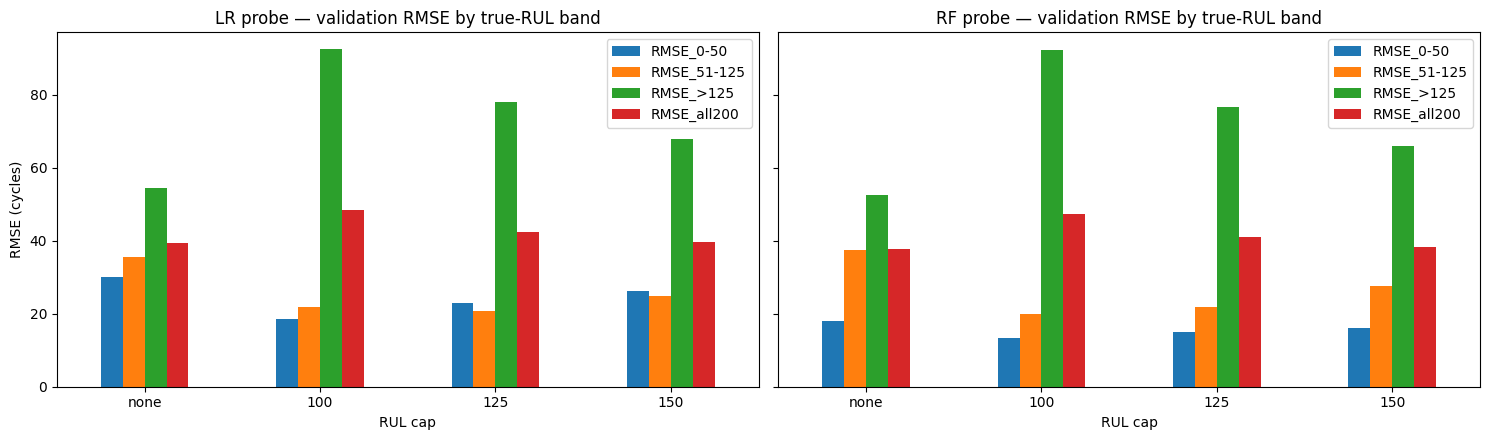

In [12]:
# Cell 12 — Does capping the training target help? (validation only)
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

prep = pp.CMAPSSPreprocessor(scaler="standard").fit(tr)
F = prep.feature_cols
va_s = prep.transform(va)
X_cut = va_s.set_index(["engine_id", "cycle"]).loc[list(zip(cuts.engine_id, cuts.cut_cycle)), F]
y_cut = cuts["true_rul"].values

rows = []
for cap in [None, 100, 125, 150]:
    tr_cap = pp.add_train_rul(d["train"], cap=cap)
    tr_cap = prep.transform(tr_cap[tr_cap["engine_id"].isin(train_ids)])
    probes = {"LR": LinearRegression(),
              "RF": RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=SEED)}
    for name, model in probes.items():
        model.fit(tr_cap[F], tr_cap["RUL"])
        pred = np.clip(model.predict(X_cut), 0, None)          # RUL can't be negative
        r = {"probe": name, "cap": "none" if cap is None else cap,
             "RMSE_all200": ev.rmse(y_cut, pred)}
        for band in ["0-50", "51-125", ">125"]:
            m = (bands == band).values
            r[f"RMSE_{band}"] = ev.rmse(y_cut[m], pred[m])
            r[f"bias_{band}"] = float(np.mean(pred[m] - y_cut[m]))   # + = late, - = early
        m = y_cut <= 125
        r["RMSE_le125"] = ev.rmse(y_cut[m], pred[m])
        r["NASA_le125_per_point"] = ev.nasa_score(y_cut[m], pred[m]) / m.sum()
        rows.append(r)

cap_results = pd.DataFrame(rows)
cap_results.to_csv(PREP_REPORT / "rul_cap_experiment.csv", index=False)
display(cap_results.round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, probe in zip(axes, ["LR", "RF"]):
    sub = cap_results[cap_results.probe == probe].set_index("cap")
    sub[["RMSE_0-50", "RMSE_51-125", "RMSE_>125", "RMSE_all200"]].plot.bar(ax=ax, rot=0)
    ax.set(title=f"{probe} probe — validation RMSE by true-RUL band", xlabel="RUL cap", ylabel="RMSE (cycles)")
fig.tight_layout()
fig.savefig(PROJECT_DIR / "reports" / "figures" / "FD001" / "11_rul_cap_experiment.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# Cell 13 — Freeze the FD001 preprocessing decisions and save with the model artifacts
CHOSEN_SCALER = "standard"
CHOSEN_CAP    = 125          # decided from Cell 12 on validation data only

final_prep = pp.CMAPSSPreprocessor(scaler=CHOSEN_SCALER).fit(tr)     # fitted on the 80 training engines
ART_DIR = PROJECT_DIR / "models" / FD / "preprocessing"
final_prep.save(ART_DIR)

metadata = {
    "dataset": FD,
    "scaler": CHOSEN_SCALER,
    "feature_cols": final_prep.feature_cols,
    "dropped_features": final_prep.dropped_features,
    "rul_cap": CHOSEN_CAP,
    "rul_cap_meaning": f"predictions near {CHOSEN_CAP} mean 'RUL >= {CHOSEN_CAP} cycles (healthy)'",
    "prediction_postprocessing": "clip predictions to >= 0",
    "split_file": "data/processed/FD001/split.json",
    "val_cut_points_file": "data/processed/FD001/val_cut_points.csv",
    "fit_on": f"{len(train_ids)} training engines (seed {SEED})",
    "metric_sign_convention": "d = predicted - true; d > 0 is late (dangerous)",
}
(ART_DIR / "pipeline_metadata.json").write_text(json.dumps(metadata, indent=2))

# Reload from disk and prove it reproduces the same transformation
reloaded = pp.CMAPSSPreprocessor.load(ART_DIR)
assert reloaded.feature_cols == final_prep.feature_cols
assert np.allclose(reloaded.transform(va)[F].values, final_prep.transform(va)[F].values)
print("✅ Saved + reload verified →", ART_DIR)
print(sorted(p.name for p in ART_DIR.iterdir()))

partB_log = {"scaler_decision": "LR/RF/XGB are scale-invariant (verified: identical LR predictions); "
                                "StandardScaler chosen for LSTM, bell-shaped features, robustness to range extremes",
             "cap_candidates": ["none", 100, 125, 150], "chosen_cap": CHOSEN_CAP,
             "selection_criterion": "RMSE / NASA / bias on test-like validation points with true RUL <= 125",
             "results_file": "reports/preprocessing/FD001/rul_cap_experiment.csv",
             "trade_off_acknowledged": "capped models underestimate engines with true RUL > cap",
             "official_test_labels": "not used"}
(PREP_REPORT / "preprocessing_log_partB.json").write_text(json.dumps(partB_log, indent=2))

✅ Saved + reload verified → /content/drive/MyDrive/Predictive_Maintenance_RUL/models/FD001/preprocessing
['pipeline_metadata.json', 'preprocessing_config.json', 'scaler.joblib']


559